# Лабораторная работа № 3. Линейная регрессия



Загрузка датасета, вывод информации по пропускам (их нет)


In [23]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
DATA_FILE=Path('california_housing_train.csv')
TARGET='median_house_value'
data=pd.read_csv(DATA_FILE)
missing_statistics=data.isna().sum().to_frame('Количество пропусков')
display(missing_statistics)


,Количество пропусков
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0


визуализайия статистики + связи числовых признаков

,count,mean,std,min,25%,50%,75%,max
longitude,17000.0,-119.562108,2.005166,-124.3500,-121.790000,-118.4900,-118.000,-114.3100
latitude,17000.0,35.625225,2.137340,32.5400,33.930000,34.2500,37.720,41.9500
housing_median_age,17000.0,28.589353,12.586937,1.0000,18.000000,29.0000,37.000,52.0000
total_rooms,17000.0,2643.664412,2179.947071,2.0000,1462.000000,2127.0000,3151.250,37937.0000
total_bedrooms,17000.0,539.410824,421.499452,1.0000,297.000000,434.0000,648.250,6445.0000
population,17000.0,1429.573941,1147.852959,3.0000,790.000000,1167.0000,1721.000,35682.0000
households,17000.0,501.221941,384.520841,1.0000,282.000000,409.0000,605.250,6082.0000
median_income,17000.0,3.883578,1.908157,0.4999,2.566375,3.5446,4.767,15.0001
median_house_value,17000.0,207300.912353,115983.764387,14999.0000,119400.000000,180400.0000,265000.000,500001.0000


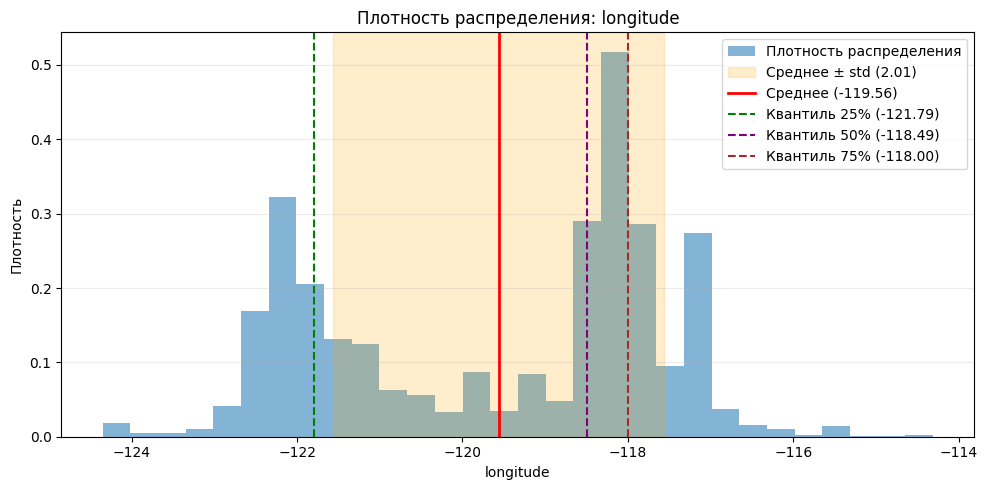

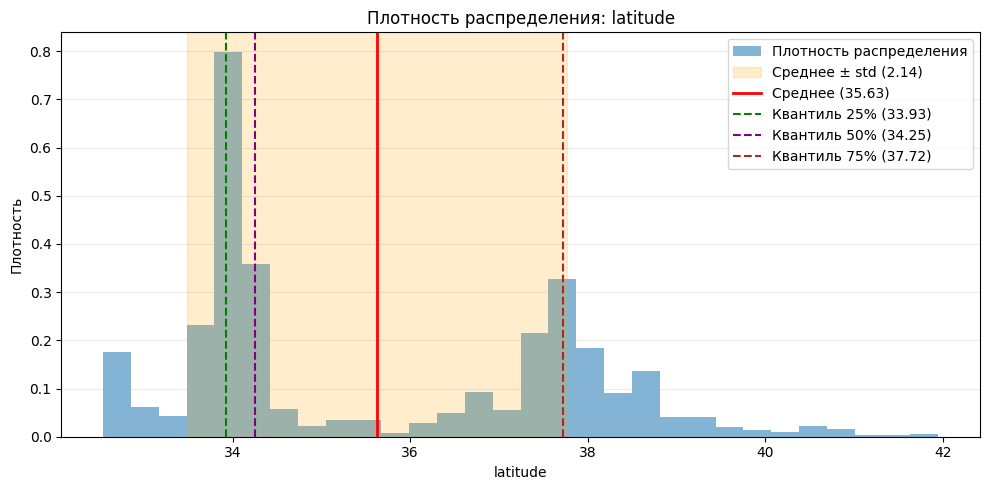

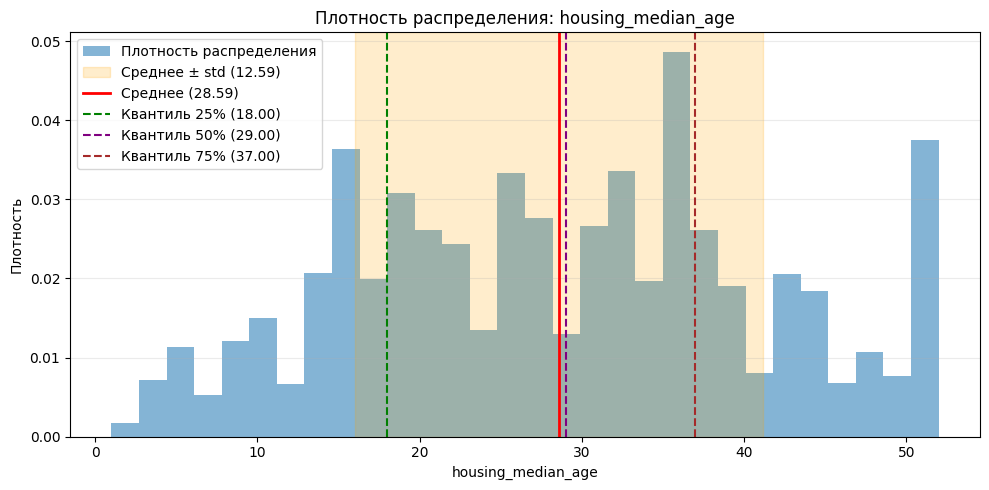

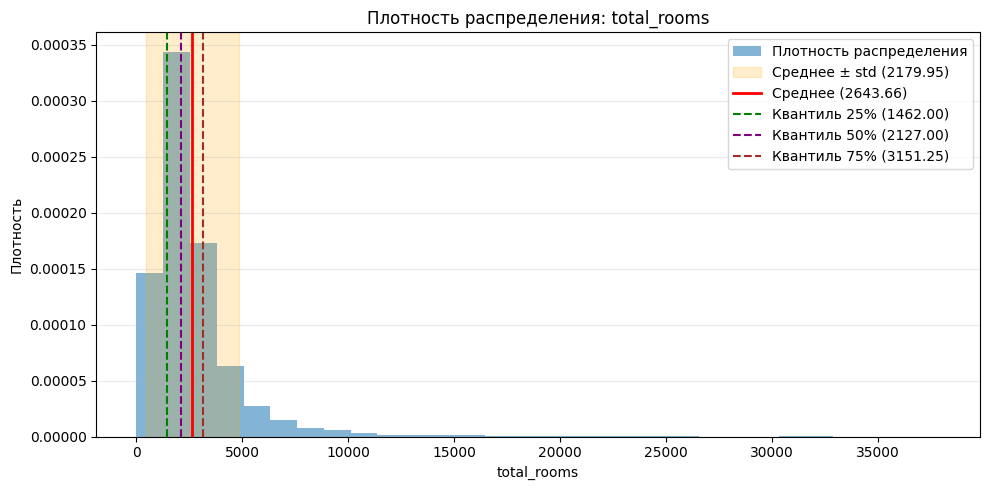

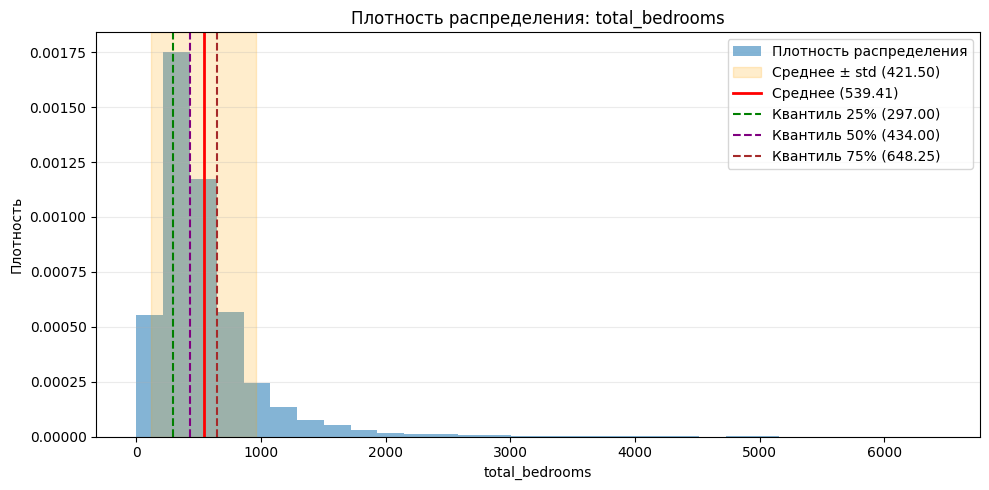

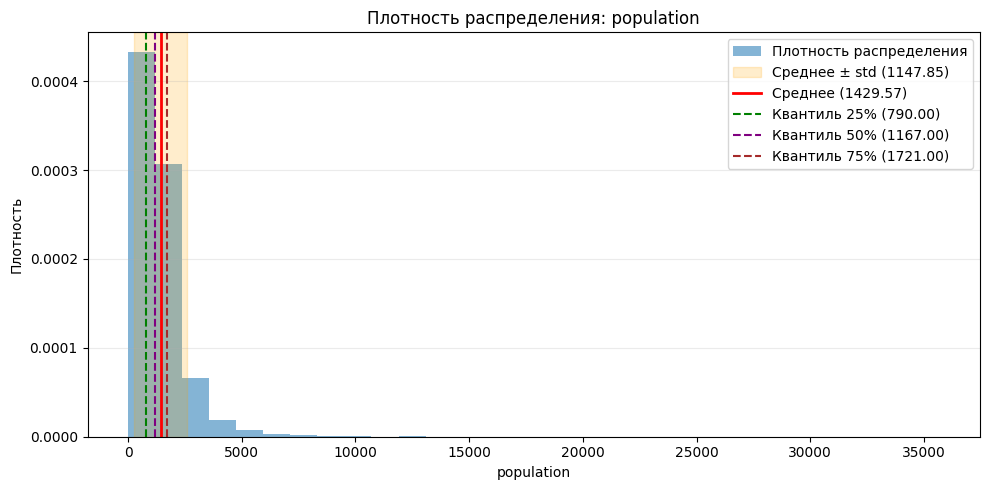

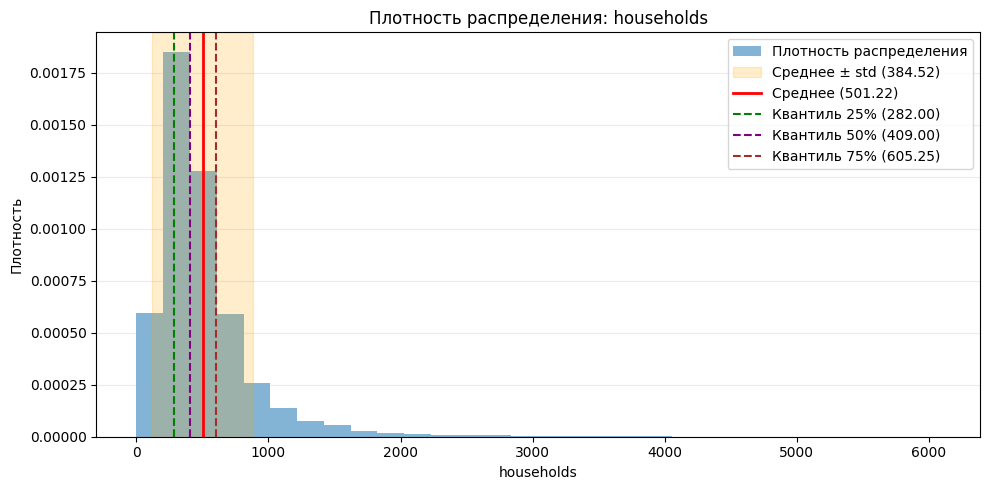

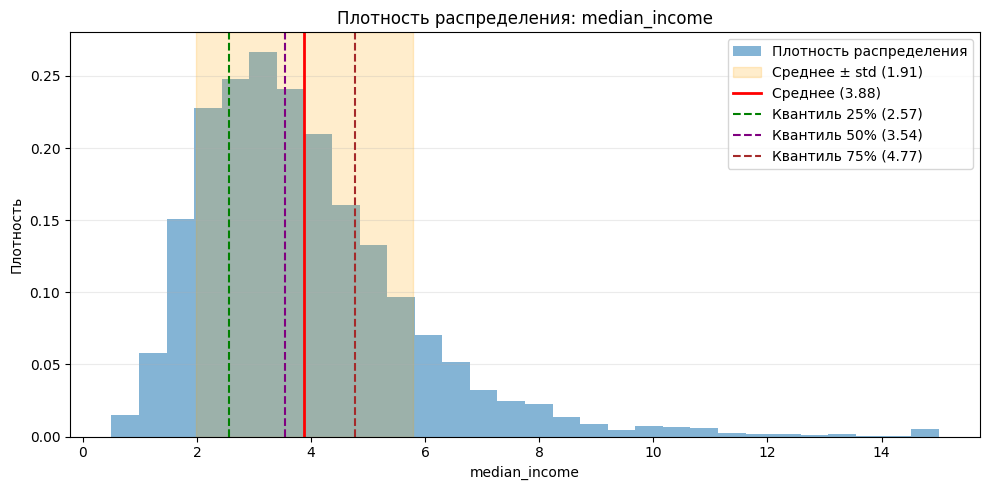

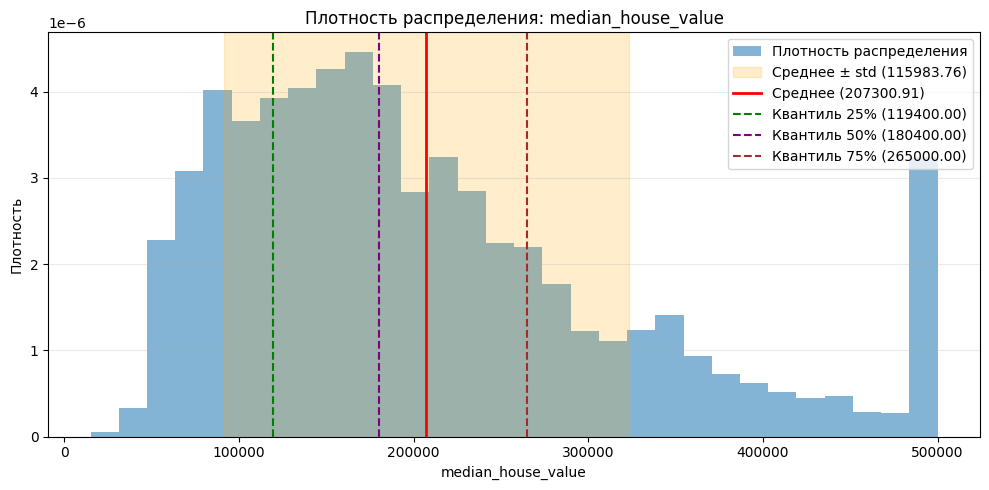

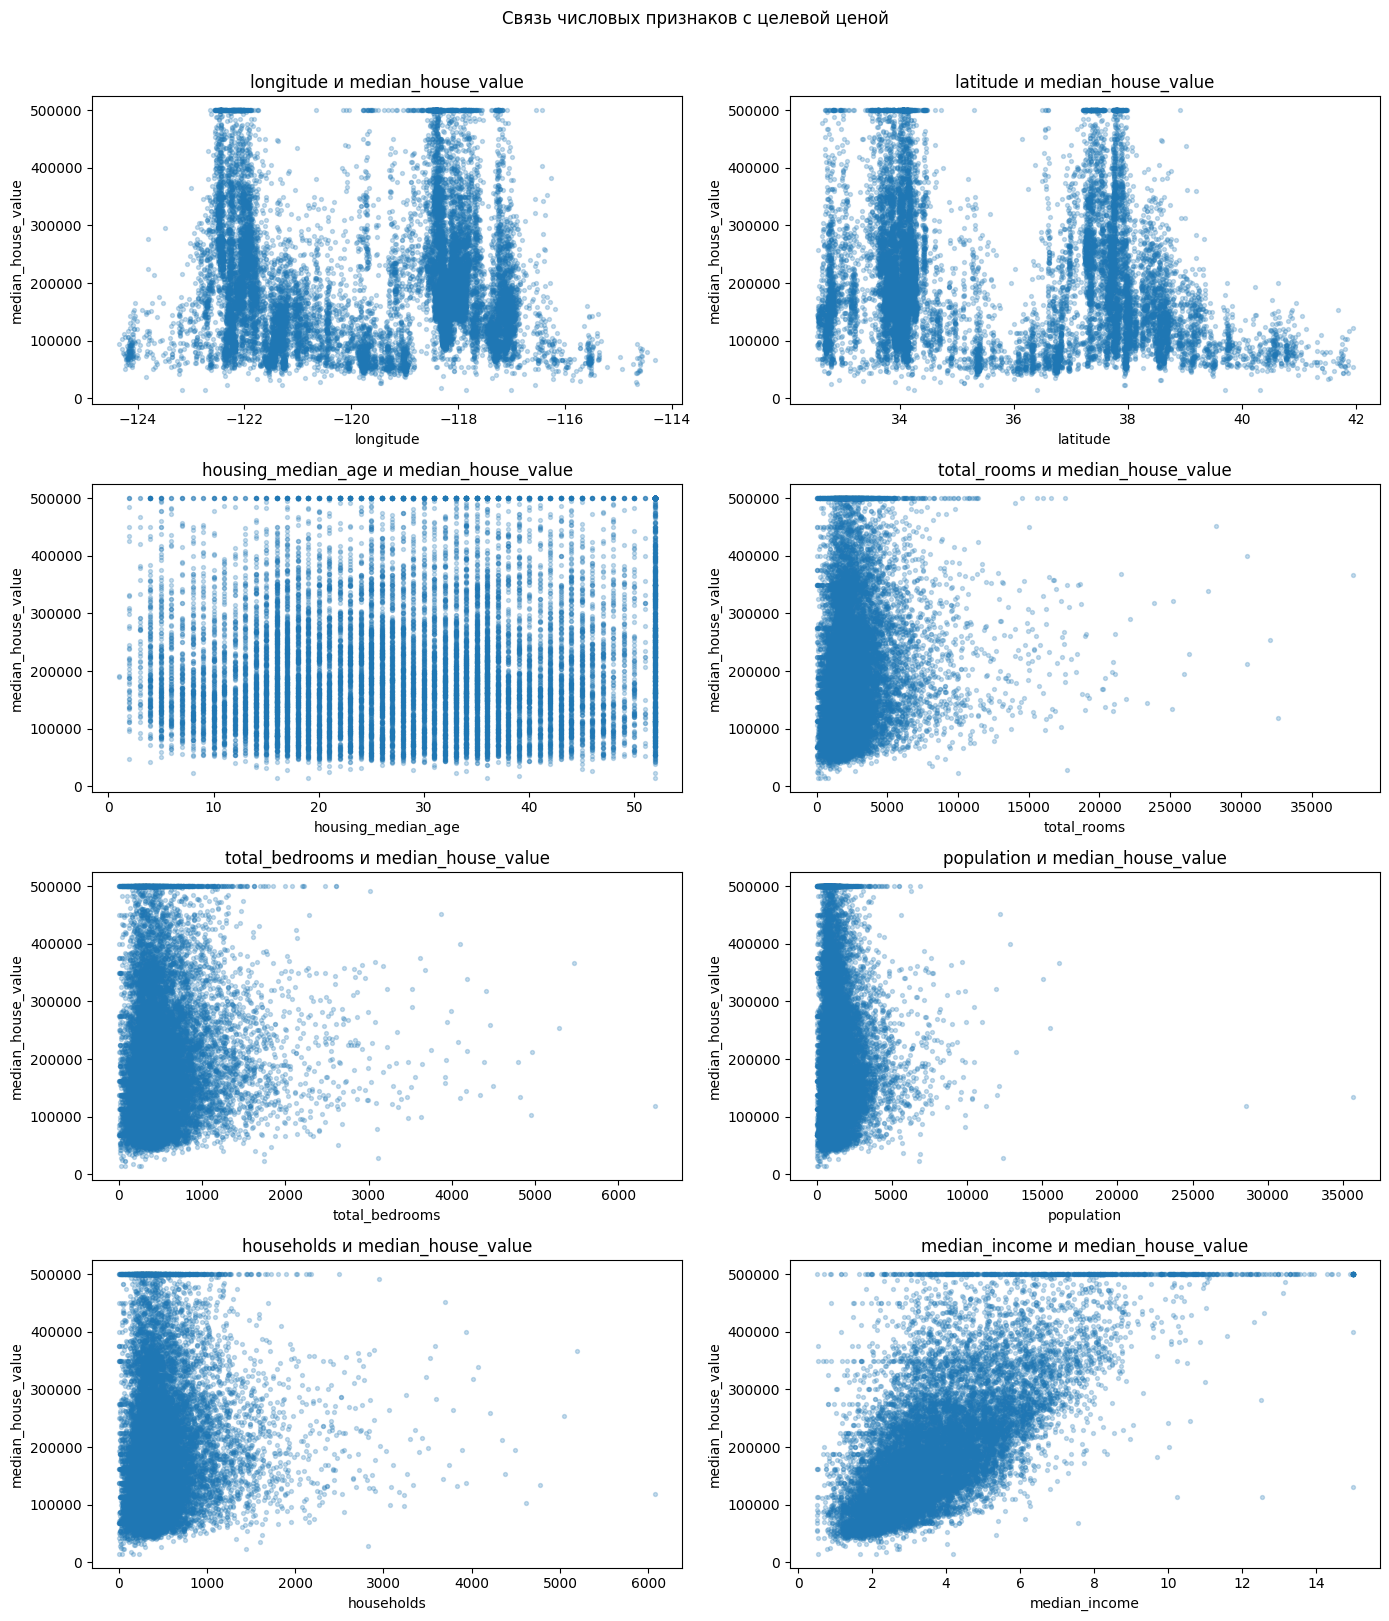

In [24]:
stats=data.describe(percentiles=[.25,.50,.75]).T
stat_columns=['count','mean','std','min','25%','50%','75%','max']
display(stats[stat_columns])


for column in data.columns:
    values=data[column]
    mean_value=stats.loc[column,'mean']
    std_value=stats.loc[column,'std']
    q25=stats.loc[column,'25%']
    median=stats.loc[column,'50%']
    q75=stats.loc[column,'75%']
    fig,ax=plt.subplots(figsize=(10,5))
    values.plot(kind='hist',bins=30,density=True,alpha=.55,ax=ax,label='Плотность распределения')
    ax.axvspan(mean_value-std_value,mean_value+std_value,color='orange',alpha=.2,label=f'Среднее ± std ({std_value:.2f})')
    ax.axvline(mean_value,color='red',linestyle='-',linewidth=2,label=f'Среднее ({mean_value:.2f})')
    ax.axvline(q25,color='green',linestyle='--',label=f'Квантиль 25% ({q25:.2f})')
    ax.axvline(median,color='purple',linestyle='--',label=f'Квантиль 50% ({median:.2f})')
    ax.axvline(q75,color='brown',linestyle='--',label=f'Квантиль 75% ({q75:.2f})')
    ax.set_title(f'Плотность распределения: {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Плотность')
    ax.legend()
    ax.grid(axis='y',alpha=.25)
    fig.tight_layout()
    plt.show()

features=[c for c in data.columns if c!=TARGET]
fig,axes=plt.subplots(4,2,figsize=(14,16))
for ax,col in zip(axes.flat,features):
    data.plot(kind='scatter',x=col,y=TARGET,alpha=.25,s=8,ax=ax)
    ax.set_title(f'{col} и {TARGET}')
    ax.set_xlabel(col)
    ax.set_ylabel(TARGET)
fig.suptitle('Связь числовых признаков с целевой ценой',y=1.01)
fig.tight_layout()
plt.show()


разбиение на обучающую и тестовую выборки

80 на 20



In [25]:
prepared = data.copy()
y = prepared.pop(TARGET)

# Синт признак
prepared['rooms_per_household'] = prepared.total_rooms / prepared.households.replace(0, np.nan)

order = np.random.default_rng(42).permutation(len(prepared))
n_test = round(.2 * len(prepared))
test_i, train_i = order[:n_test], order[n_test:]

X_train, X_test = prepared.iloc[train_i].copy(), prepared.iloc[test_i].copy()
y_train, y_test = y.iloc[train_i].copy(), y.iloc[test_i].copy()

print(f'Train: {len(X_train)}; test: {len(X_test)}')

Train: 13600; test: 3400


нормировка данных

In [26]:
means = X_train.mean()
stds = X_train.std(ddof=0).replace(0, 1.)

X_train = (X_train - means) / stds
X_test = (X_test - means) / stds

display(X_train.describe().T[['mean', 'std', 'min', 'max']])

,mean,std,min,max
longitude,-4.378197e-16,1.000037,-2.361209,2.619206
latitude,-1.207923e-15,1.000037,-1.445331,2.959736
housing_median_age,-9.325873e-17,1.000037,-2.192649,1.859546
total_rooms,-8.463818e-17,1.000037,-1.225761,16.408612
total_bedrooms,-5.433562e-17,1.000037,-1.287331,14.114690
population,-4.702121e-17,1.000037,-1.283895,24.539929
households,-5.015596e-17,1.000037,-1.316619,14.698796
median_income,-7.471148e-17,1.000037,-1.774546,5.848284
rooms_per_household,-1.912196e-16,1.000037,-1.734416,51.551760


реализация МНК



In [27]:
def design(x):
    return np.column_stack([np.ones(len(x)),x])
def fit_ols(x,target):
    X=design(x)
    gram=X.T@X
    rhs=X.T@target
    try:
        return np.linalg.solve(gram,rhs)
    except np.linalg.LinAlgError:
        return np.linalg.pinv(gram)@rhs
def predict(x,b):
    return design(x)@b
def r2(actual,predicted):
    sse=np.sum((actual-predicted)**2)
    sst=np.sum((actual-actual.mean())**2)
    return float('nan') if sst==0 else float(1-sse/sst)

## Этап 6. Обучение и сравнение четырёх моделей

1 - только доход

2 - доход и координаты

3 - все признаки

4 (бонус) - еще синтетический




,Модель,Признаки,R² train,R² test
0,Модель 1: только доход,median_income,0.471078,0.508019
1,Модель 2: доход и координаты,"median_income, longitude, latitude",0.583354,0.608163
2,Модель 3: все исходные признаки,"longitude, latitude, housing_median_age, total...",0.639107,0.647530
3,Модель 4: модель 3 плюс бонус,"longitude, latitude, housing_median_age, total...",0.640466,0.647654



Модель 1: только доход
 intercept: 207,032.010
 median_income: 79,363.008

Модель 2: доход и координаты
 intercept: 207,032.010
 median_income: 69,462.743
 longitude: -100,340.090
 latitude: -104,331.573

Модель 3: все исходные признаки
 intercept: 207,032.010
 longitude: -86,914.017
 latitude: -92,652.686
 housing_median_age: 13,856.101
 total_rooms: -15,630.140
 total_bedrooms: 43,689.577
 population: -48,450.108
 households: 25,173.589
 median_income: 75,712.675

Модель 4: модель 3 плюс бонус
 intercept: 207,032.010
 longitude: -88,757.840
 latitude: -94,880.714
 housing_median_age: 13,944.780
 total_rooms: -18,808.995
 total_bedrooms: 36,002.978
 population: -48,567.954
 households: 36,140.629
 median_income: 74,333.983
 rooms_per_household: 5,324.143


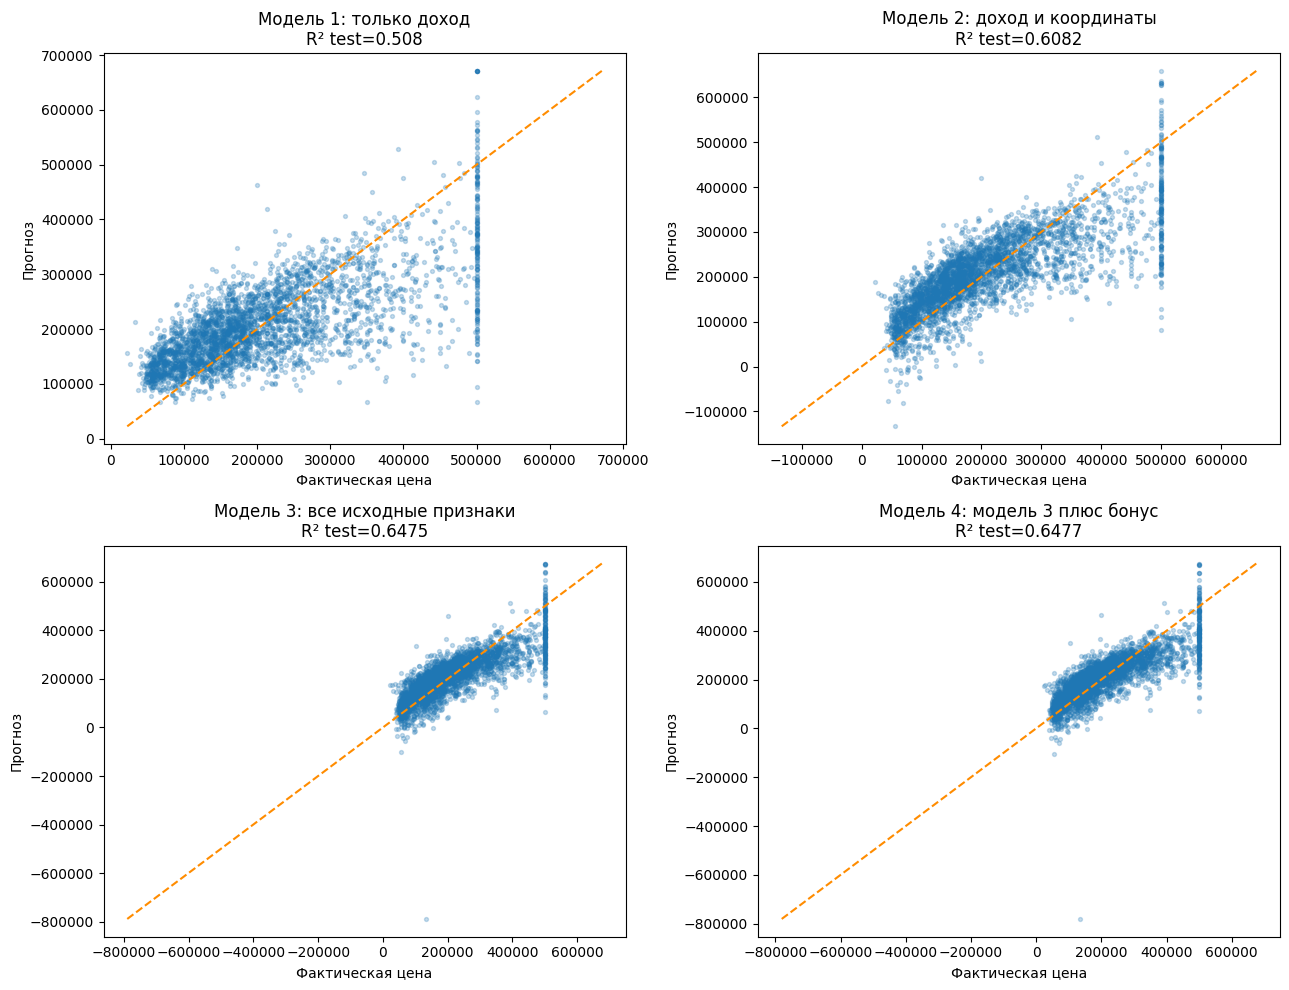

In [28]:
original=['longitude','latitude','housing_median_age','total_rooms','total_bedrooms','population','households','median_income']
specs=[('Модель 1: только доход',['median_income']),('Модель 2: доход и координаты',['median_income','longitude','latitude']),('Модель 3: все исходные признаки',original),('Модель 4: модель 3 плюс бонус',original+['rooms_per_household'])]
results=[]
for model_name,cols in specs:
    b=fit_ols(X_train[cols].to_numpy(),y_train.to_numpy())
    train_pred=predict(X_train[cols].to_numpy(),b)
    test_pred=predict(X_test[cols].to_numpy(),b)
    results.append({'name':model_name,'cols':cols,'b':b,'pred':test_pred,'train_r2':r2(y_train.to_numpy(),train_pred),'test_r2':r2(y_test.to_numpy(),test_pred)})
display(pd.DataFrame([{'Модель':r['name'],'Признаки':', '.join(r['cols']),'R² train':r['train_r2'],'R² test':r['test_r2']} for r in results]))
for result in results:
    print(chr(10)+result['name'])
    for feature,value in zip(['intercept']+result['cols'],result['b']):
        print(f' {feature}: {value:,.3f}')
fig,axes=plt.subplots(2,2,figsize=(13,10))
y_test_array=y_test.to_numpy()
for ax,result in zip(axes.flat,results):
    frame=pd.DataFrame({'Фактическая цена':y_test_array,'Прогноз':result['pred']})
    frame.plot(kind='scatter',x='Фактическая цена',y='Прогноз',alpha=.25,s=8,ax=ax)
    lo=min(frame.min())
    hi=max(frame.max())
    ax.plot([lo,hi],[lo,hi],color='darkorange',linestyle='--')
    ax.set_title(result['name']+chr(10)+'R² test='+str(round(result['test_r2'],4)))
fig.tight_layout()
plt.show()